# Heart Disease Dataset (Heart.csv) - Exploration, Clustering and Modelling
**Course assignment**

**Name:** Nacer Eddine Tazmouti  
**Student number:** 220208840

**Dataset:** Heart.csv (Cleveland heart-disease data, 303 patients, 13 clinical variables + `AHD` = angiographic heart disease Yes/No).
**Continuous target chosen:** `MaxHR` (maximum heart rate achieved during the exercise test).

## 0. Data cleaning (Gemini coding-assistant step)
The brief asks us to have the Gemini coding assistant clean the data. Prompt used (paste into Gemini in Colab to reproduce / screenshot):

> *"I uploaded Heart.csv. Drop the unnamed index column, report missing values per column, drop rows with missing values, convert the string target AHD ('Yes'/'No') to 1/0, convert Ca from float to int, strip whitespace in the string columns ChestPain and Thal, and print the cleaned dtypes."*

The cell below is the cleaning code that results from that prompt. Problems found: an unnamed index column, 4 missing `Ca`, 2 missing `Thal`, string-typed target `AHD`, `Ca` stored as float.

In [1]:
from IPython.display import display
import pandas as pd, numpy as np, warnings, itertools, matplotlib
import matplotlib.pyplot as plt, seaborn as sns, ppscore as pps, umap, hdbscan
from scipy import stats
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split, RepeatedKFold, cross_val_score
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from statsmodels.stats.outliers_influence import variance_inflation_factor
warnings.filterwarnings('ignore'); RS = 42; np.random.seed(RS)
sns.set_theme(style='whitegrid', context='notebook')
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 30)

/usr/local/lib/python3.12/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
raw = pd.read_csv('Heart.csv')
print(raw.shape); display(raw.head(10)); print(raw.dtypes); print('\nMissing values per column:'); print(raw.isna().sum()[raw.isna().sum()>0])

(303, 15)


,Unnamed: 0,Age,Sex,ChestPain,RestBP,Chol,Fbs,RestECG,MaxHR,ExAng,Oldpeak,Slope,Ca,Thal,AHD
0,1,63,1,typical,145,233,1,2,150,0,2.3,3,0.0,fixed,No
1,2,67,1,asymptomatic,160,286,0,2,108,1,1.5,2,3.0,normal,Yes
2,3,67,1,asymptomatic,120,229,0,2,129,1,2.6,2,2.0,reversable,Yes
3,4,37,1,nonanginal,130,250,0,0,187,0,3.5,3,0.0,normal,No
4,5,41,0,nontypical,130,204,0,2,172,0,1.4,1,0.0,normal,No
5,6,56,1,nontypical,120,236,0,0,178,0,0.8,1,0.0,normal,No
6,7,62,0,asymptomatic,140,268,0,2,160,0,3.6,3,2.0,normal,Yes
7,8,57,0,asymptomatic,120,354,0,0,163,1,0.6,1,0.0,normal,No
8,9,63,1,asymptomatic,130,254,0,2,147,0,1.4,2,1.0,reversable,Yes
9,10,53,1,asymptomatic,140,203,1,2,155,1,3.1,3,0.0,reversable,Yes


Unnamed: 0      int64
Age             int64
Sex             int64
ChestPain         str
RestBP          int64
Chol            int64
Fbs             int64
RestECG         int64
MaxHR           int64
ExAng           int64
Oldpeak       float64
Slope           int64
Ca            float64
Thal              str
AHD               str
dtype: object

Missing values per column:
Ca      4
Thal    2
dtype: int64


In [3]:
df = raw.drop(columns=raw.columns[0])            # unnamed row-index column
df = df.dropna().reset_index(drop=True)          # 4 missing Ca + 2 missing Thal (6 rows, 2% of data)
df['AHD'] = (df['AHD'] == 'Yes').astype(int)     # string target -> 0/1
df['Ca'] = df['Ca'].astype(int)                  # float -> integer count of vessels
for c in ['ChestPain', 'Thal']: df[c] = df[c].astype(str).str.strip()
print('Clean shape:', df.shape, '| missing:', int(df.isna().sum().sum())); display(df.dtypes.to_frame('dtype').T)

Clean shape: (297, 14) | missing: 0


,Age,Sex,ChestPain,RestBP,Chol,Fbs,RestECG,MaxHR,ExAng,Oldpeak,Slope,Ca,Thal,AHD
dtype,int64,int64,str,int64,int64,int64,int64,int64,int64,float64,int64,int64,str,int64


## 1. Exploration
### 1.1 Tabular representation

In [4]:
display(df.head(10))

,Age,Sex,ChestPain,RestBP,Chol,Fbs,RestECG,MaxHR,ExAng,Oldpeak,Slope,Ca,Thal,AHD
0,63,1,typical,145,233,1,2,150,0,2.3,3,0,fixed,0
1,67,1,asymptomatic,160,286,0,2,108,1,1.5,2,3,normal,1
2,67,1,asymptomatic,120,229,0,2,129,1,2.6,2,2,reversable,1
3,37,1,nonanginal,130,250,0,0,187,0,3.5,3,0,normal,0
4,41,0,nontypical,130,204,0,2,172,0,1.4,1,0,normal,0
5,56,1,nontypical,120,236,0,0,178,0,0.8,1,0,normal,0
6,62,0,asymptomatic,140,268,0,2,160,0,3.6,3,2,normal,1
7,57,0,asymptomatic,120,354,0,0,163,1,0.6,1,0,normal,0
8,63,1,asymptomatic,130,254,0,2,147,0,1.4,2,1,reversable,1
9,53,1,asymptomatic,140,203,1,2,155,1,3.1,3,0,reversable,1


Cleaned data: **297 rows x 14 columns** (6 rows with missing `Ca`/`Thal` dropped, about 2 %, so no imputation bias). 5 variables are continuous (`Age, RestBP, Chol, MaxHR, Oldpeak`), 3 are binary (`Sex, Fbs, ExAng`) plus the binary label `AHD`, and `RestECG, Slope, Ca, ChestPain, Thal` are categorical/ordinal.
### 1.2 Descriptive statistics

In [5]:
CONT = ['Age', 'RestBP', 'Chol', 'MaxHR', 'Oldpeak']
BINCAT = ['Sex', 'Fbs', 'RestECG', 'ExAng', 'Slope', 'Ca', 'AHD', 'ChestPain', 'Thal']
desc = df[CONT].describe().T; desc['skew'] = df[CONT].skew(); desc['kurtosis'] = df[CONT].kurt(); display(desc.round(2))
for c in BINCAT: print(c, df[c].value_counts().to_dict())

,count,mean,std,min,25%,50%,75%,max,skew,kurtosis
Age,297.0,54.54,9.05,29.0,48.0,56.0,61.0,77.0,-0.22,-0.52
RestBP,297.0,131.69,17.76,94.0,120.0,130.0,140.0,200.0,0.70,0.81
Chol,297.0,247.35,52.00,126.0,211.0,243.0,276.0,564.0,1.12,4.44
MaxHR,297.0,149.60,22.94,71.0,133.0,153.0,166.0,202.0,-0.54,-0.05
Oldpeak,297.0,1.06,1.17,0.0,0.0,0.8,1.6,6.2,1.25,1.51


Sex {1: 201, 0: 96}
Fbs {0: 254, 1: 43}
RestECG {0: 147, 2: 146, 1: 4}
ExAng {0: 200, 1: 97}
Slope {1: 139, 2: 137, 3: 21}
Ca {0: 174, 1: 65, 2: 38, 3: 20}
AHD {0: 160, 1: 137}
ChestPain {'asymptomatic': 142, 'nonanginal': 83, 'nontypical': 49, 'typical': 23}
Thal {'normal': 164, 'reversable': 115, 'fixed': 18}


* `Chol` (skew 1.12, kurtosis 4.4) and `Oldpeak` (skew 1.25, 0 for many patients) are right-skewed with outliers (Chol up to 564, Oldpeak up to 6.2) -> rank-based or nonlinear association metrics are safer for these.
* `MaxHR` is slightly left-skewed (mean 149.6, sd 22.9) and has a healthy spread, which makes it a good regression target.
* Classes are fairly balanced (AHD: 160 No / 137 Yes); 68 % of patients are male; `Fbs`, `RestECG=1` and `Thal=fixed` are rare categories.
### 1.3 Initial PairGrid

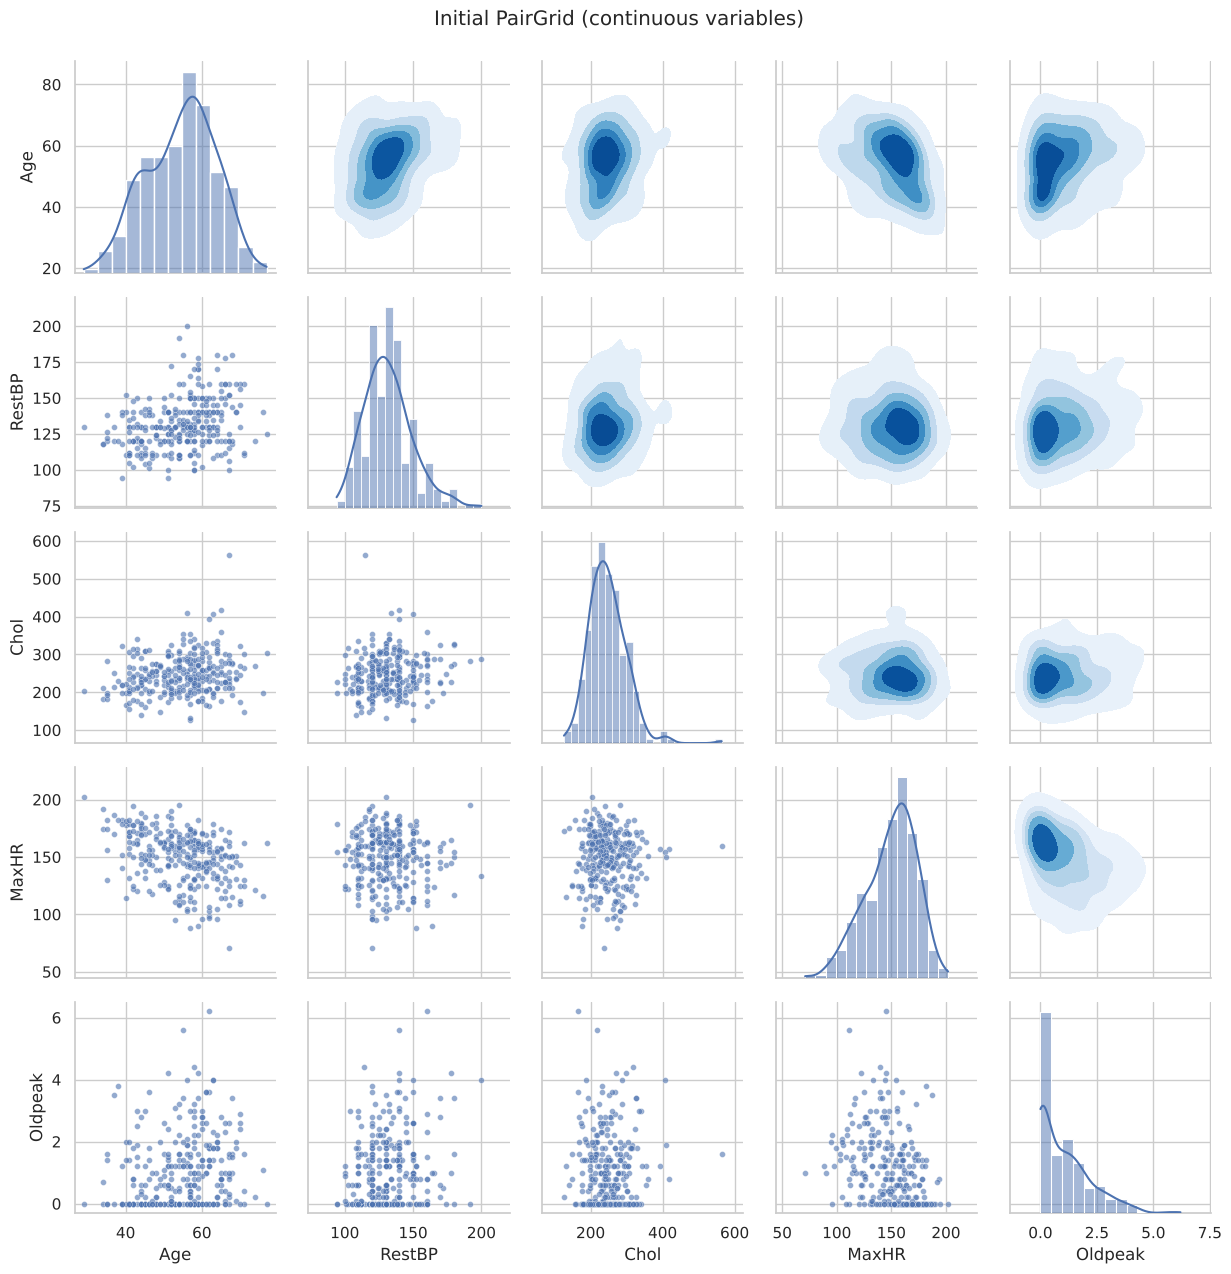

In [6]:
g = sns.PairGrid(df[CONT], diag_sharey=False, corner=False)
g.map_lower(sns.scatterplot, s=18, alpha=.6); g.map_upper(sns.kdeplot, fill=True, levels=6, cmap='Blues'); g.map_diag(sns.histplot, kde=True)
g.fig.suptitle('Initial PairGrid (continuous variables)', y=1.02); plt.savefig('figs/01_pairgrid_initial.png', dpi=110, bbox_inches='tight'); plt.show()

**Reading the PairGrid.** Almost all pairs are weak and diffuse clouds. The visible structure: `Age` vs `MaxHR` has a clear negative linear trend; `MaxHR` vs `Oldpeak` is negative and fan-shaped (large `Oldpeak` only occurs at low/medium `MaxHR`); `Age` vs `RestBP` is mildly positive; `Chol` is essentially unrelated to everything, and `Oldpeak` is piled at 0 (zero-inflated), which violates the normality/linearity assumed by Pearson.
### 1.4 Association heatmaps and the right metric per pair

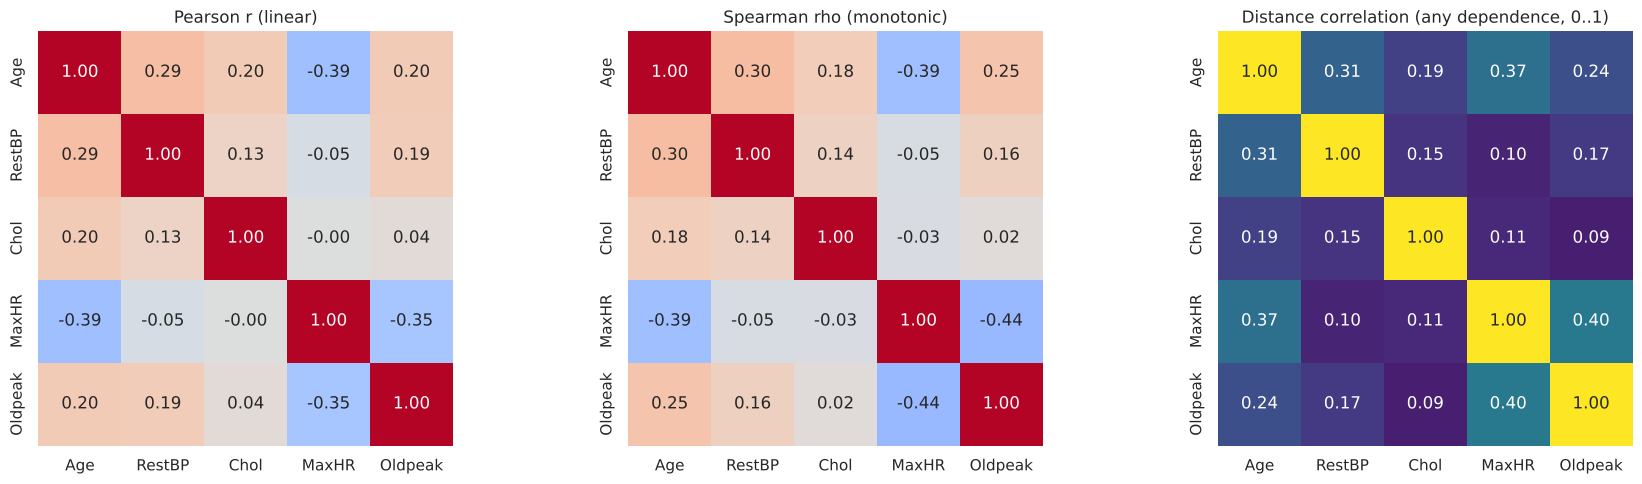

,var 1,var 2,Pearson,Spearman,dCor,suggested metric
0,Age,RestBP,0.29,0.30,0.31,Pearson
1,Age,Chol,0.20,0.18,0.19,Spearman
2,Age,MaxHR,-0.39,-0.39,0.37,Pearson
3,Age,Oldpeak,0.20,0.25,0.24,Spearman
4,RestBP,Chol,0.13,0.14,0.15,Spearman
5,RestBP,MaxHR,-0.05,-0.05,0.10,Pearson
6,RestBP,Oldpeak,0.19,0.16,0.17,Spearman
7,Chol,MaxHR,-0.00,-0.03,0.11,Spearman
8,Chol,Oldpeak,0.04,0.02,0.09,Spearman
9,MaxHR,Oldpeak,-0.35,-0.44,0.40,Spearman


In [7]:
def dcor(x, y):
    x, y = np.asarray(x, float), np.asarray(y, float)
    a = np.abs(x[:, None] - x[None, :]); b = np.abs(y[:, None] - y[None, :])
    A = a - a.mean(0) - a.mean(1)[:, None] + a.mean(); B = b - b.mean(0) - b.mean(1)[:, None] + b.mean()
    return np.sqrt((A*B).mean() / np.sqrt((A*A).mean() * (B*B).mean()))
pear = df[CONT].corr(); spear = df[CONT].corr(method='spearman')
dc = pd.DataFrame([[dcor(df[a], df[b]) for b in CONT] for a in CONT], index=CONT, columns=CONT)
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
for a, m, t, kw in zip(ax, [pear, spear, dc], ['Pearson r (linear)', 'Spearman rho (monotonic)', 'Distance correlation (any dependence, 0..1)'], [dict(vmin=-1, vmax=1, cmap='coolwarm'), dict(vmin=-1, vmax=1, cmap='coolwarm'), dict(vmin=0, vmax=1, cmap='viridis')]):
    sns.heatmap(m, annot=True, fmt='.2f', ax=a, square=True, cbar=False, **kw); a.set_title(t)
plt.tight_layout(); plt.savefig('figs/02_assoc_continuous.png', dpi=110); plt.show()
# per-pair table with a recommended metric
rows = []
for a, b in itertools.combinations(CONT, 2):
    r, _ = stats.pearsonr(df[a], df[b]); s, _ = stats.spearmanr(df[a], df[b]); k = dcor(df[a], df[b])
    metric = 'Spearman' if (abs(s) - abs(r) > .05 or abs(df[[a, b]].skew()).max() > 1) else 'Pearson'
    if k - max(abs(r), abs(s)) > .08: metric = 'Distance corr.'
    rows.append([a, b, round(r, 2), round(s, 2), round(k, 2), metric])
pair_tbl = pd.DataFrame(rows, columns=['var 1', 'var 2', 'Pearson', 'Spearman', 'dCor', 'suggested metric']); display(pair_tbl)

**Comment per pair and suggested metric** (table above):

| Pair | Pattern | Metric to use |
|---|---|---|
| Age-RestBP | weak/moderate positive, linear | Pearson (0.29) |
| Age-MaxHR | moderate negative, linear, no outliers | Pearson (-0.39) |
| Age-Chol | weak positive, Chol has outliers | Spearman (0.18) |
| Age-Oldpeak | weak positive, Oldpeak zero-inflated | Spearman (0.25 > Pearson 0.20) |
| MaxHR-Oldpeak | negative, monotonic but not linear (fan shape) | Spearman (-0.44 vs Pearson -0.35); dCor 0.40 confirms |
| RestBP-Chol, RestBP-Oldpeak | very weak | Spearman |
| RestBP-MaxHR, Chol-MaxHR, Chol-Oldpeak | no meaningful association (|r|<0.05) but dCor 0.09-0.11 is not exactly 0, so no hidden nonlinear structure beyond noise | any; Spearman is the safe default |

Overall, **Spearman** is the appropriate default for this dataset because of skewed/zero-inflated variables; distance correlation never reveals a strong relationship that Pearson/Spearman miss, so the relationships are essentially monotonic.

For the full mixed-type table (numeric, binary and categorical variables together) we use |Spearman| for numeric-numeric, the correlation ratio eta for numeric-categorical and Cramer's V for categorical-categorical:

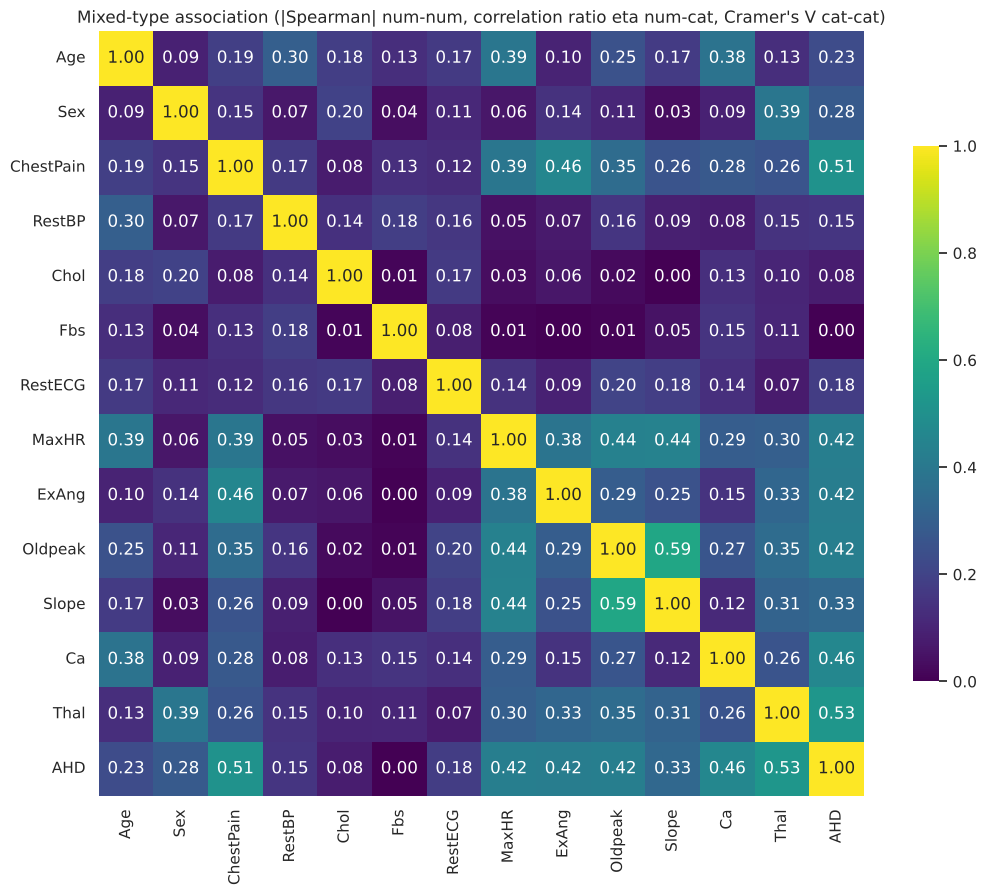

In [8]:
def cramers_v(x, y):
    ct = pd.crosstab(x, y); chi2 = stats.chi2_contingency(ct, correction=False)[0]; n = ct.values.sum()
    return np.sqrt(chi2 / (n * (min(ct.shape) - 1)))
def eta(cat, num):
    g = [num[cat == c] for c in np.unique(cat)]; ss_b = sum(len(x) * (x.mean() - num.mean())**2 for x in g); return np.sqrt(ss_b / ((num - num.mean())**2).sum())
ALL = ['Age', 'Sex', 'ChestPain', 'RestBP', 'Chol', 'Fbs', 'RestECG', 'MaxHR', 'ExAng', 'Oldpeak', 'Slope', 'Ca', 'Thal', 'AHD']
NUMERIC = set(CONT) | {'Ca', 'Slope'}  # ordinal counts treated as numeric (Spearman)
CATEG = set(ALL) - NUMERIC
M = pd.DataFrame(1.0, index=ALL, columns=ALL)
for a, b in itertools.combinations(ALL, 2):
    if a in NUMERIC and b in NUMERIC: v = abs(stats.spearmanr(df[a], df[b])[0])
    elif a in CATEG and b in CATEG: v = cramers_v(df[a], df[b])
    else: c, n = (a, b) if a in CATEG else (b, a); v = eta(df[c].values, df[n].astype(float))
    M.loc[a, b] = M.loc[b, a] = v
plt.figure(figsize=(11, 9)); sns.heatmap(M, annot=True, fmt='.2f', cmap='viridis', vmin=0, vmax=1, square=True, cbar_kws={'shrink': .7})
plt.title('Mixed-type association (|Spearman| num-num, correlation ratio eta num-cat, Cramer\'s V cat-cat)'); plt.tight_layout(); plt.savefig('figs/03_assoc_mixed.png', dpi=110); plt.show()

The strongest associations in the dataset are between categorical variables (e.g. `ChestPain`-`AHD`, `Thal`-`AHD`, `Slope`-`Oldpeak`, `ExAng`-`ChestPain`), which is typical for clinical data. `MaxHR` is related to `Slope`, `Oldpeak`, `AHD`, `Age`, `ChestPain` and `ExAng` (0.38-0.44), and is unrelated to `Chol`, `RestBP`, `Fbs`, `Sex`.
### 1.5 Directional association: conventional metrics vs Predictive Power Score (PPS)

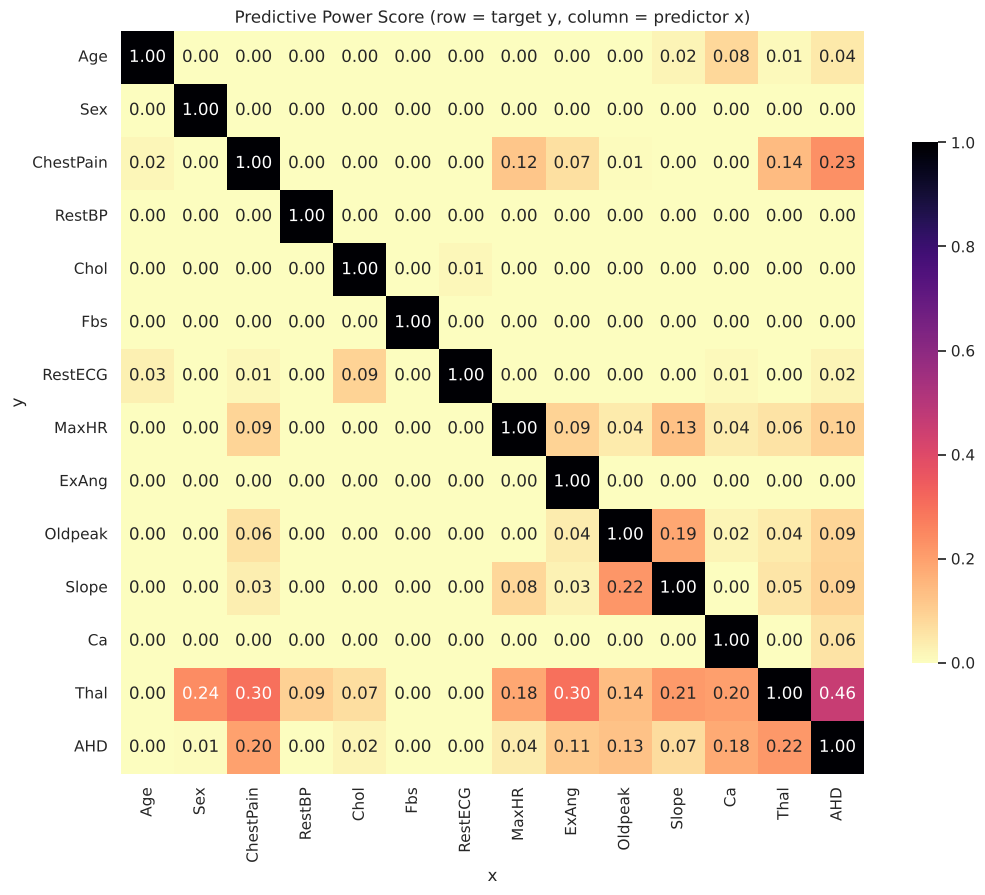

,Spearman/eta/V with MaxHR,PPS (x -> MaxHR),PPS (MaxHR -> x),asymmetry
Slope,0.44,0.13,0.08,0.04
Oldpeak,0.44,0.04,0.00,0.04
AHD,0.42,0.10,0.04,0.06
Age,0.39,0.00,0.00,0.00
ChestPain,0.39,0.09,0.12,-0.03
ExAng,0.38,0.09,0.00,0.09
Thal,0.30,0.06,0.18,-0.13
Ca,0.29,0.04,0.00,0.04
RestECG,0.14,0.00,0.00,0.00
Sex,0.06,0.00,0.00,0.00


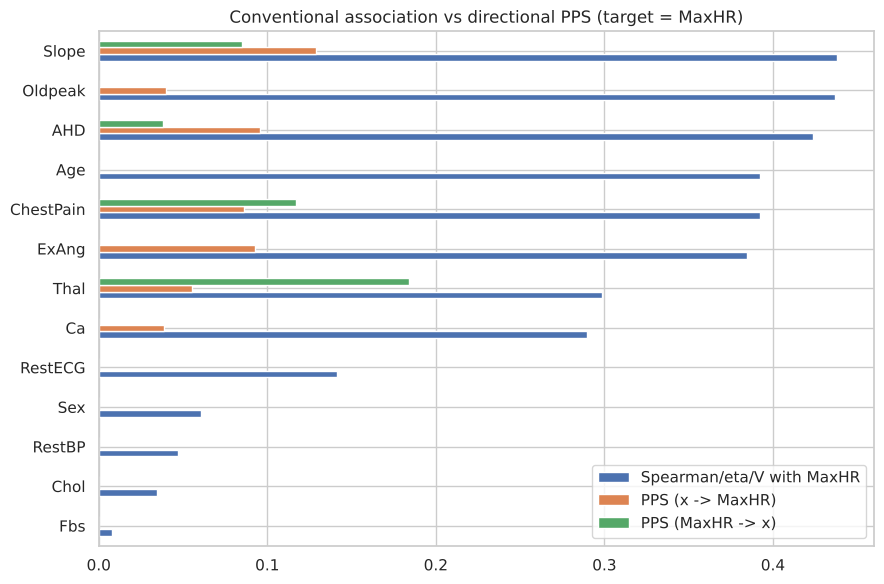

In [9]:
TARGET = 'MaxHR'
pps_mat = pps.matrix(df[ALL])[['x', 'y', 'ppscore']].pivot(index='y', columns='x', values='ppscore').loc[ALL, ALL]
plt.figure(figsize=(11, 9)); sns.heatmap(pps_mat, annot=True, fmt='.2f', cmap='magma_r', vmin=0, vmax=1, square=True, cbar_kws={'shrink': .7})
plt.title('Predictive Power Score (row = target y, column = predictor x)'); plt.tight_layout(); plt.savefig('figs/04_pps.png', dpi=110); plt.show()
cmp = pd.DataFrame({'Spearman/eta/V with MaxHR': M[TARGET].drop(TARGET), 'PPS (x -> MaxHR)': pps_mat.loc[TARGET].drop(TARGET), 'PPS (MaxHR -> x)': pps_mat[TARGET].drop(TARGET)})
cmp['asymmetry'] = cmp['PPS (x -> MaxHR)'] - cmp['PPS (MaxHR -> x)']; display(cmp.sort_values('Spearman/eta/V with MaxHR', ascending=False).round(2))
ax = cmp[['Spearman/eta/V with MaxHR', 'PPS (x -> MaxHR)', 'PPS (MaxHR -> x)']].sort_values('Spearman/eta/V with MaxHR').plot.barh(figsize=(9, 6)); ax.set_title('Conventional association vs directional PPS (target = MaxHR)')
plt.tight_layout(); plt.savefig('figs/05_conv_vs_pps.png', dpi=110); plt.show()

**Comments on directionality (target = `MaxHR`).**
* Conventional metrics are symmetric by construction, so they cannot say which variable predicts which. PPS is asymmetric (row = target, column = predictor).
* PPS values are low everywhere (max 0.18). That is expected: PPS uses a cross-validated decision tree on only 297 rows and is scored against a naive baseline, so it is conservative. Yet the *ranking* is informative: `Slope` (0.13), `AHD` (0.10), `ChestPain` (0.09) and `ExAng` (0.09) are the best single predictors of `MaxHR`.
* PPS gives **0 for `Age` and `Oldpeak`** even though their correlation with `MaxHR` is -0.39 and -0.44. The linear effect is real but a depth-limited tree on one noisy variable cannot beat the median baseline -> the relationship is a smooth linear trend with a lot of scatter, which a linear model captures much better than a tree. Conventional correlation is the more appropriate metric for these two.
* Asymmetry: `ExAng` (+0.09), `AHD` (+0.06) predict `MaxHR` better than the reverse, which makes physiological sense (exercise angina/disease limit heart rate, a heart rate does not determine angina). `Thal` is the opposite: `MaxHR` -> `Thal` (0.18) is higher than `Thal` -> `MaxHR` (0.06), but with 3 imbalanced categories this is mostly a base-rate artefact of the class imbalance, so we do not read it causally.
* `Chol`, `RestBP`, `Fbs`, `Sex`, `RestECG` have no predictive power for `MaxHR` under either metric.
### 1.6 Choice of the target and a "nice" predictor set
`MaxHR` was chosen as the continuous target because it has clinically meaningful drivers, a wide spread and several moderately associated predictors (neither trivially predictable nor pure noise). To select the linear model's predictors we used **forward selection with repeated 5-fold CV R2** (keep adding a variable only if CV R2 improves by at least 0.005) and checked collinearity with VIF.

In [10]:
cand = ['Age', 'RestBP', 'Chol', 'Oldpeak', 'Sex', 'Fbs', 'RestECG', 'ExAng', 'Slope', 'Ca', 'AHD']
rkf = RepeatedKFold(n_splits=5, n_repeats=5, random_state=RS)
sel, best, trace = [], -9, []
while True:
    scores = {c: cross_val_score(LinearRegression(), df[sel + [c]], df[TARGET], cv=rkf, scoring='r2').mean() for c in cand if c not in sel}
    if not scores: break
    c, s = max(scores.items(), key=lambda kv: kv[1])
    if s - best < 0.005: break
    sel.append(c); best = s; trace.append((c, round(s, 3)))
print('Forward selection trace (feature added, CV R2):', trace); LIN_FEATS = sel
Xv = df[LIN_FEATS].astype(float).assign(const=1.0)
print('VIF:', {c: round(variance_inflation_factor(Xv.values, i), 2) for i, c in enumerate(Xv.columns) if c != 'const'})

Forward selection trace (feature added, CV R2): [('AHD', np.float64(0.151)), ('Age', np.float64(0.244)), ('ExAng', np.float64(0.291)), ('Slope', np.float64(0.326)), ('RestBP', np.float64(0.332))]
VIF: {'AHD': np.float64(1.35), 'Age': np.float64(1.14), 'ExAng': np.float64(1.24), 'Slope': np.float64(1.16), 'RestBP': np.float64(1.11)}


Selected set: **`AHD, Age, ExAng, Slope, RestBP`**. They are "nice" because (i) every VIF is about 1.1-1.35, so no collinearity, (ii) they have mixed information sources (disease label, demographics, exercise response, ECG slope) and (iii) the CV R2 rises from 0.15 -> 0.33 and flattens. `Oldpeak` is not chosen despite its strong correlation because it is largely redundant with `Slope`/`ExAng`/`AHD` once those are in. `RestBP` adds only 0.006; it is kept because it passes the rule and does not hurt. *(Caveat: selection was done on the full data with CV, so S1's CV R2 is slightly optimistic.)*
### 1.7 3D PCA and 3D UMAP: target-shaded and HDBSCAN-shaded
The embeddings use all features **except the target** (one-hot encoded + standardised), so cluster labels contain no information about `MaxHR`. HDBSCAN is run on the 3D UMAP embedding (n_neighbors=30, min_dist=0.1, min_cluster_size=20).

PCA explained variance: [0.23  0.098 0.085] | total 0.413


Cluster sizes (-1 = noise): {-1: 1, 0: 47, 1: 39, 2: 81, 3: 77, 4: 52}


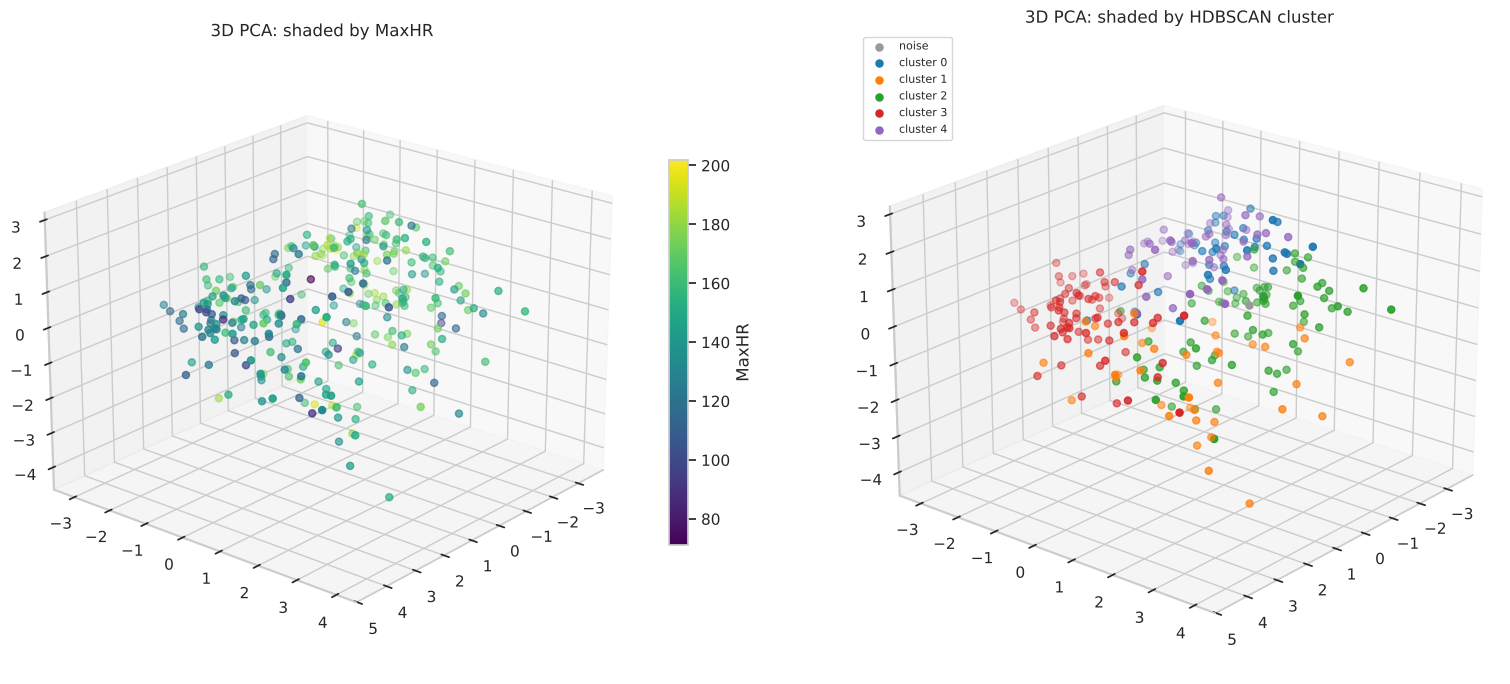

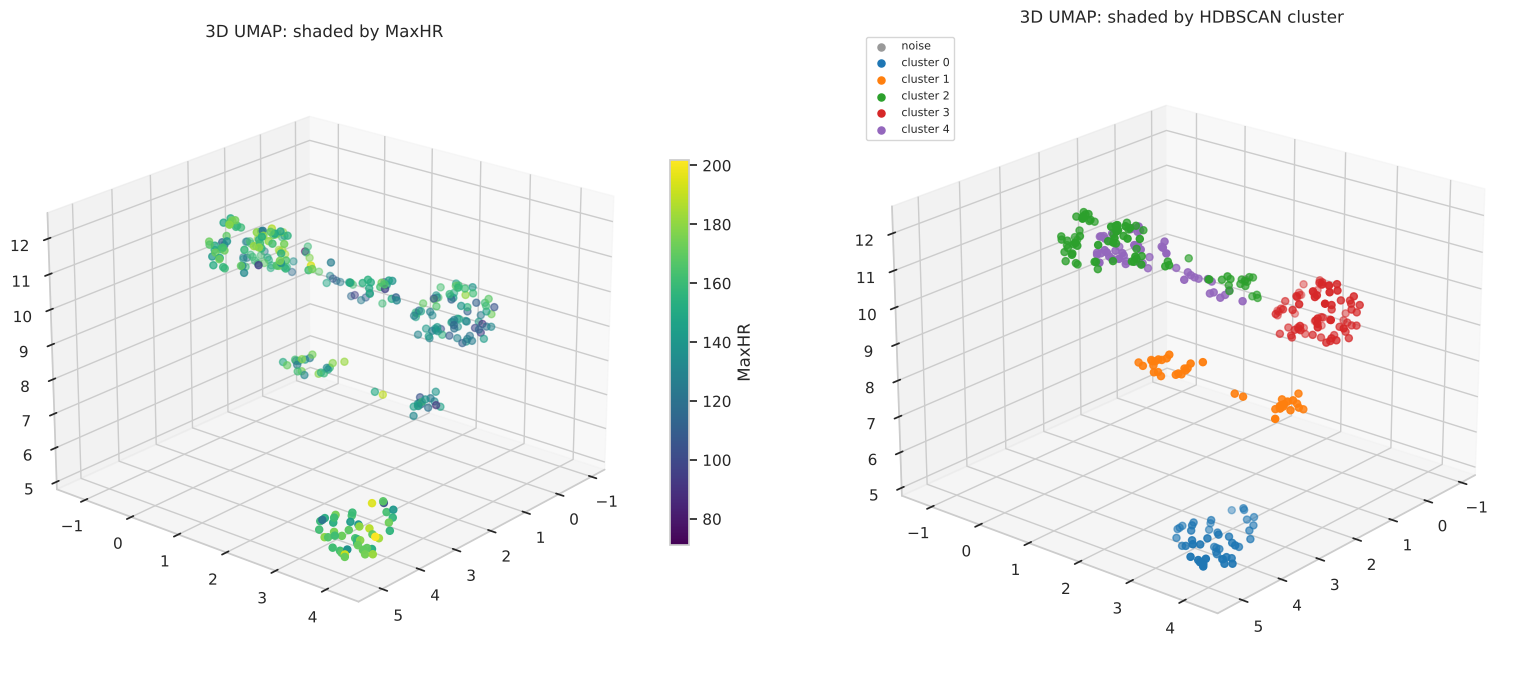

In [11]:
X_all = pd.get_dummies(df.drop(columns=[TARGET]), columns=['ChestPain', 'Thal'], dtype=float)
Z = StandardScaler().fit_transform(X_all)   # clustering/embedding uses features only (target excluded -> no leakage)
pca = PCA(3, random_state=RS).fit(Z); P = pca.transform(Z); print('PCA explained variance:', pca.explained_variance_ratio_.round(3), '| total', pca.explained_variance_ratio_.sum().round(3))
U = umap.UMAP(n_components=3, n_neighbors=30, min_dist=0.1, random_state=RS).fit_transform(Z)
cl = hdbscan.HDBSCAN(min_cluster_size=20, min_samples=5).fit_predict(U); df['cluster'] = cl
print('Cluster sizes (-1 = noise):', pd.Series(cl).value_counts().sort_index().to_dict())
def plot3d(E, name, fn):
    fig = plt.figure(figsize=(16, 7))
    ax = fig.add_subplot(121, projection='3d'); sc = ax.scatter(*E.T, c=df[TARGET], cmap='viridis', s=26); fig.colorbar(sc, ax=ax, shrink=.6, label=TARGET); ax.set_title(f'{name}: shaded by {TARGET}')
    ax = fig.add_subplot(122, projection='3d'); pal = sns.color_palette('tab10', 10)
    for k in sorted(set(cl)): m = cl == k; ax.scatter(*E[m].T, s=26, color=(.6, .6, .6) if k == -1 else pal[k], label='noise' if k == -1 else f'cluster {k}')
    ax.legend(loc='upper left', fontsize=8); ax.set_title(f'{name}: shaded by HDBSCAN cluster')
    for a in fig.axes[:]:
        if hasattr(a, 'view_init'): a.view_init(22, 40)
    plt.tight_layout(); plt.savefig(fn, dpi=110); plt.show()
plot3d(P, '3D PCA', 'figs/06_pca3d.png'); plot3d(U, '3D UMAP', 'figs/07_umap3d.png')

**Data geometry and clusters.**
* **PCA:** the first 3 components explain only 41 % of the variance (23 %, 9.8 %, 8.5 %) -> the data are not low-dimensional; there is no clean linear structure. The `MaxHR` colour gradient is visible along the main axes (low `MaxHR` toward the diseased/high-Oldpeak side) but it is a gradual shading, not separated blobs.
* **UMAP:** a manifold of **5 compact clusters** (+1 noise point) appears, with small cluster sizes of 39-81. The target shading shows that `MaxHR` varies *between* clusters (ANOVA F = 13.8, p = 2e-10) but a lot of variation remains *within* them.
* The clusters are mainly **built from the categorical variables**: each one almost exactly matches a `ChestPain` type or a `Thal` pattern (profile tables below). That is why UMAP/HDBSCAN separates them so cleanly, one-hot variables create discrete groups.
### 1.8 Cluster profiles

In [12]:
prof = df.groupby('cluster').agg(n=('Age', 'size'), Age=('Age', 'mean'), MaxHR=('MaxHR', 'mean'), MaxHR_sd=('MaxHR', 'std'), Oldpeak=('Oldpeak', 'mean'), Chol=('Chol', 'mean'), RestBP=('RestBP', 'mean'), Sex_male=('Sex', 'mean'), ExAng=('ExAng', 'mean'), Ca=('Ca', 'mean'), AHD=('AHD', 'mean'), Slope=('Slope', 'mean')).round(2); display(prof)
display(pd.crosstab(df.cluster, df.ChestPain)); display(pd.crosstab(df.cluster, df.Thal))
print('ANOVA MaxHR ~ cluster:', stats.f_oneway(*[g[TARGET] for k, g in df.groupby('cluster') if k != -1]))

,n,Age,MaxHR,MaxHR_sd,Oldpeak,Chol,RestBP,Sex_male,ExAng,Ca,AHD,Slope
cluster,,,,,,,,,,,,
-1,1,62.00,106.00,NaN,1.90,294.00,138.00,0.00,0.00,3.00,1.00,2.00
0,47,51.13,164.36,17.71,0.33,246.17,127.66,0.62,0.06,0.30,0.17,1.28
1,39,56.15,145.62,23.04,1.46,233.87,139.54,0.87,0.31,0.74,0.49,1.85
2,81,53.83,155.95,19.02,0.82,245.59,130.19,0.58,0.12,0.46,0.20,1.51
3,77,55.49,138.10,20.59,1.66,249.29,134.13,0.84,0.66,1.13,0.91,1.79
4,52,55.98,147.21,25.64,0.86,257.50,128.08,0.50,0.40,0.60,0.44,1.58


ChestPain,asymptomatic,nonanginal,nontypical,typical
cluster,,,,
-1,1,0,0,0
0,0,0,47,0
1,12,2,2,23
2,0,81,0,0
3,77,0,0,0
4,52,0,0,0


Thal,fixed,normal,reversable
cluster,,,
-1,0,1,0
0,0,39,8
1,18,13,8
2,0,59,22
3,0,0,77
4,0,52,0


ANOVA MaxHR ~ cluster: F_onewayResult(statistic=np.float64(13.839157241533426), pvalue=np.float64(2.4018971786655455e-10))


* **Cluster 0 (n=47):** all `nontypical` chest pain, young-ish (51), lowest disease rate (17 % AHD), **highest MaxHR (164)**, almost no exercise angina.
* **Cluster 2 (n=81):** all `nonanginal` pain, low Oldpeak, 20 % AHD, high MaxHR (156).
* **Cluster 3 (n=77):** all `asymptomatic` + `reversable` Thal, 91 % AHD, 66 % exercise angina, high Oldpeak, **lowest MaxHR (138)**.
* **Cluster 4 (n=52):** `asymptomatic` + normal Thal, 44 % AHD, MaxHR 147 with the **largest spread (sd 25.6)**.
* **Cluster 1 (n=39):** mostly `typical` angina + all `fixed` Thal defects, 87 % male, MaxHR 146.
* The cluster means of MaxHR range from 138 to 164, a 26 bpm gap, so the clusters carry real information on the target.
### 1.9 Cluster-aware PairGrid and revised PairGrid

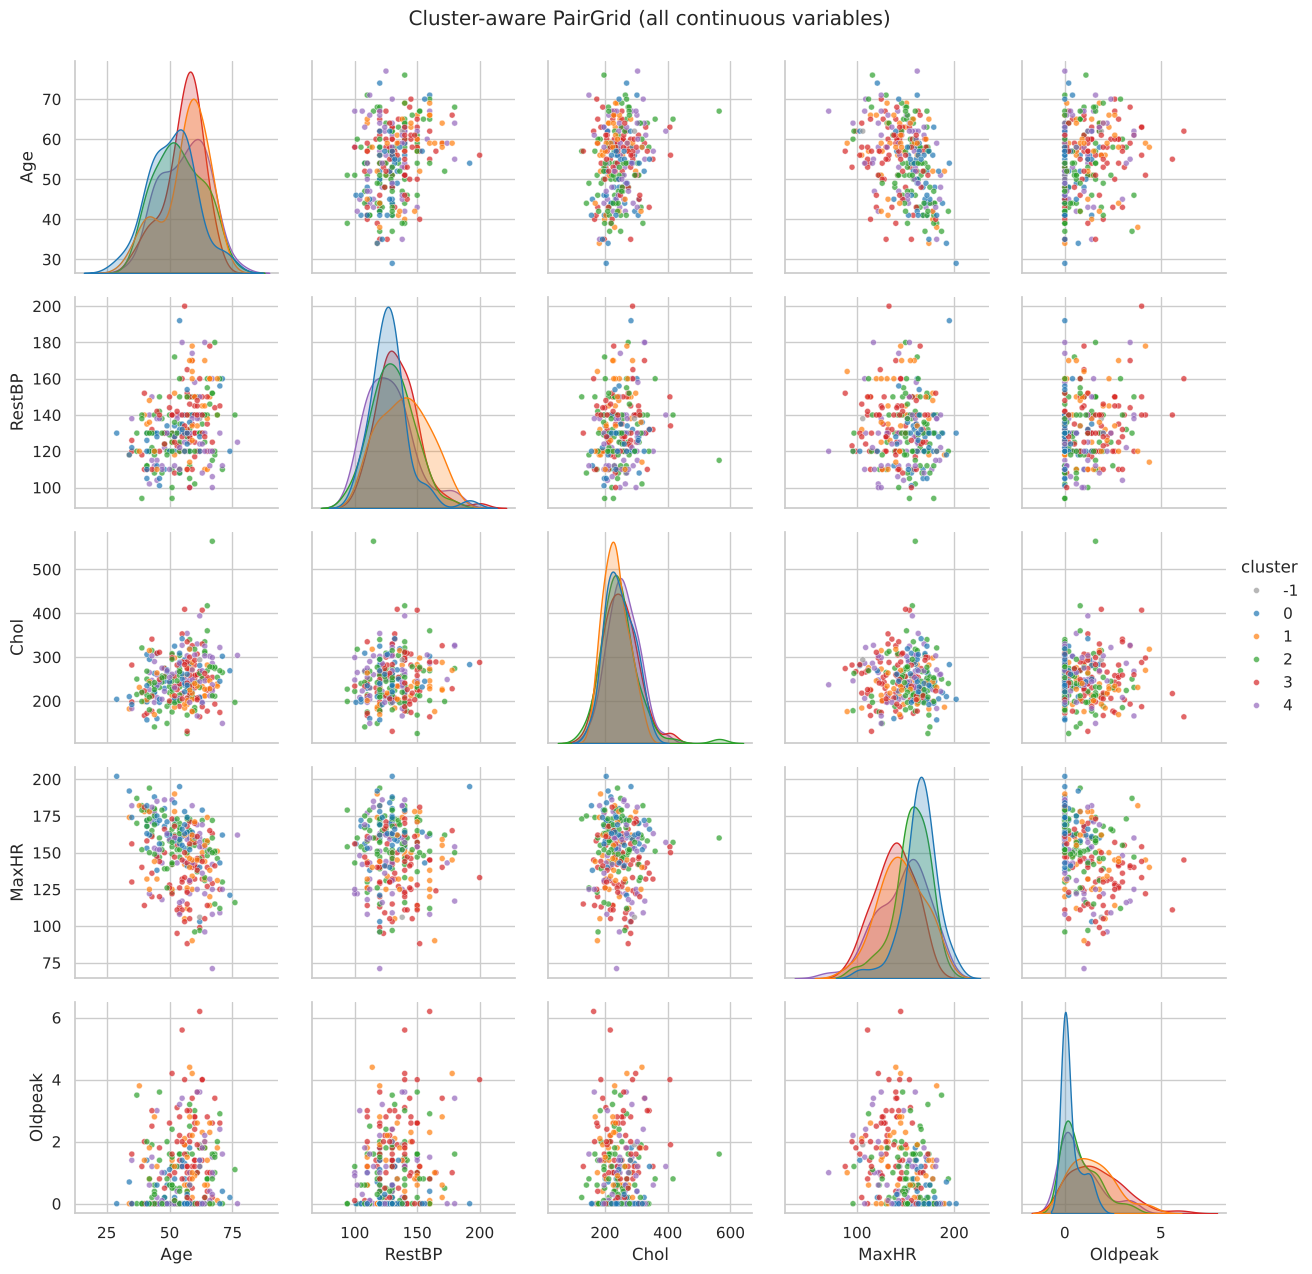

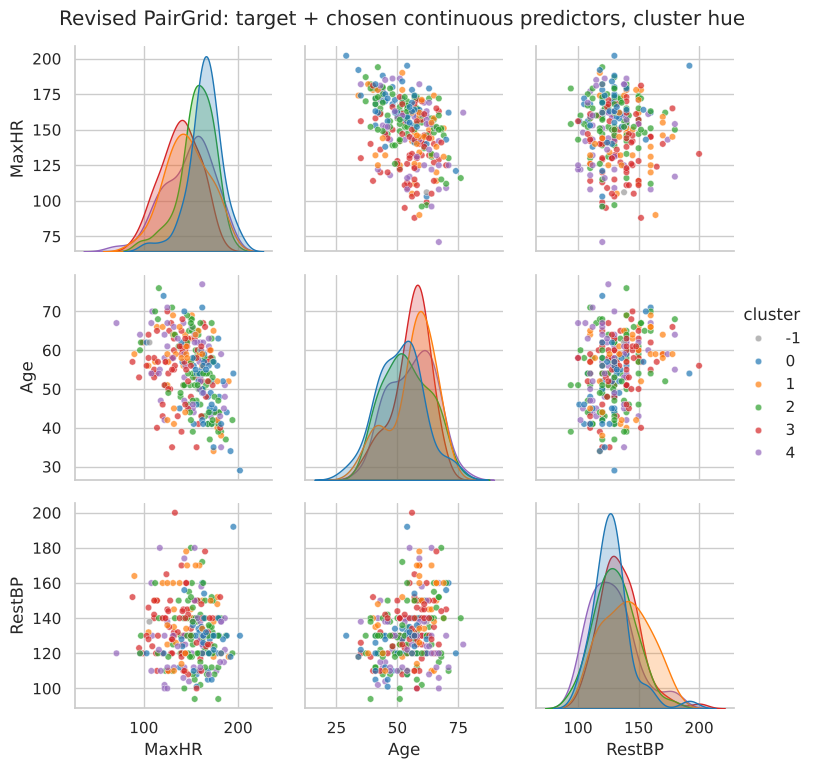

In [13]:
pal = {k: (.6, .6, .6) if k == -1 else sns.color_palette('tab10')[k] for k in sorted(df.cluster.unique())}
g = sns.PairGrid(df[CONT + ['cluster']], hue='cluster', palette=pal, diag_sharey=False); g.map_lower(sns.scatterplot, s=18, alpha=.7); g.map_upper(sns.scatterplot, s=18, alpha=.7); g.map_diag(sns.kdeplot, fill=True, alpha=.25, common_norm=False); g.add_legend()
g.fig.suptitle('Cluster-aware PairGrid (all continuous variables)', y=1.02); plt.savefig('figs/08_pairgrid_cluster.png', dpi=110, bbox_inches='tight'); plt.show()
REV = [TARGET] + [c for c in LIN_FEATS if c in CONT] 
g = sns.PairGrid(df[REV + ['cluster']], hue='cluster', palette=pal, diag_sharey=False); g.map_lower(sns.regplot if False else sns.scatterplot, s=22, alpha=.7); g.map_upper(sns.scatterplot, s=22, alpha=.7); g.map_diag(sns.kdeplot, fill=True, alpha=.25, common_norm=False); g.add_legend()
g.fig.suptitle('Revised PairGrid: target + chosen continuous predictors, cluster hue', y=1.02); plt.savefig('figs/09_pairgrid_revised.png', dpi=110, bbox_inches='tight'); plt.show()

**Cluster-aware patterns.** Colouring by cluster shows that the clusters sit at different *levels* but their trends are nearly parallel: e.g. in `Age` vs `MaxHR` cluster 0 and 2 (healthy-ish) sit higher than cluster 3, while the negative slope exists inside most clusters (r = -0.55, -0.51, -0.43, -0.29; cluster 3 is the exception, -0.07). In `MaxHR` vs `Oldpeak`, the overall correlation (-0.35) is **weaker inside every cluster (-0.06 to -0.40)**: much of the pooled relationship comes from between-cluster differences (cluster 3 has both high Oldpeak and low MaxHR). The `Chol` cloud is structureless in every cluster. The revised PairGrid (target + continuous selected predictors, cluster hue):

The revised grid (second figure above) confirms: after conditioning on cluster, `Age`-`MaxHR` stays the one robust linear partial pattern; `RestBP`-`MaxHR` flips between slightly positive (cluster 0: +0.18, cluster 4: +0.10) and slightly negative (cluster 1: -0.16), i.e. no consistent partial relationship.
## 2. Modelling (target = MaxHR)
Common protocol: 75/25 train/test split (random_state=42) for the reported **test R2**, plus **repeated 5-fold CV** (5x5) for a more stable estimate because 74 test points are noisy. Random forests: 500 trees, default depth. Cluster information is added as one-hot columns (the single HDBSCAN noise point becomes its own column).
* **S1:** linear regression on `AHD, Age, ExAng, Slope, RestBP`
* **S2:** random forest on the same 5 variables
* **S3:** random forest on all 13 original features (18 columns after one-hot), no cluster information
* **S4:** random forest on all features + one-hot cluster information (24 columns)

Linear coefficients: {'AHD': np.float64(-10.667), 'Age': np.float64(-0.872), 'ExAng': np.float64(-8.713), 'Slope': np.float64(-9.254), 'RestBP': np.float64(0.159)} intercept 197.82


,n_features,train_R2,test_R2,CV_R2_mean,CV_R2_sd,test_RMSE,test_MAE,corr_pred_actual
scenario,,,,,,,,
S1 Linear (selected vars),5,0.376,0.352,0.332,0.093,16.493,13.603,0.631
S2 RF (same vars as linear),5,0.900,0.035,0.167,0.140,20.132,16.163,0.460
"S3 RF (all features, no cluster)",18,0.907,0.278,0.308,0.130,17.412,14.582,0.575
S4 RF (all features + cluster one-hot),24,0.909,0.257,0.310,0.130,17.662,14.850,0.562


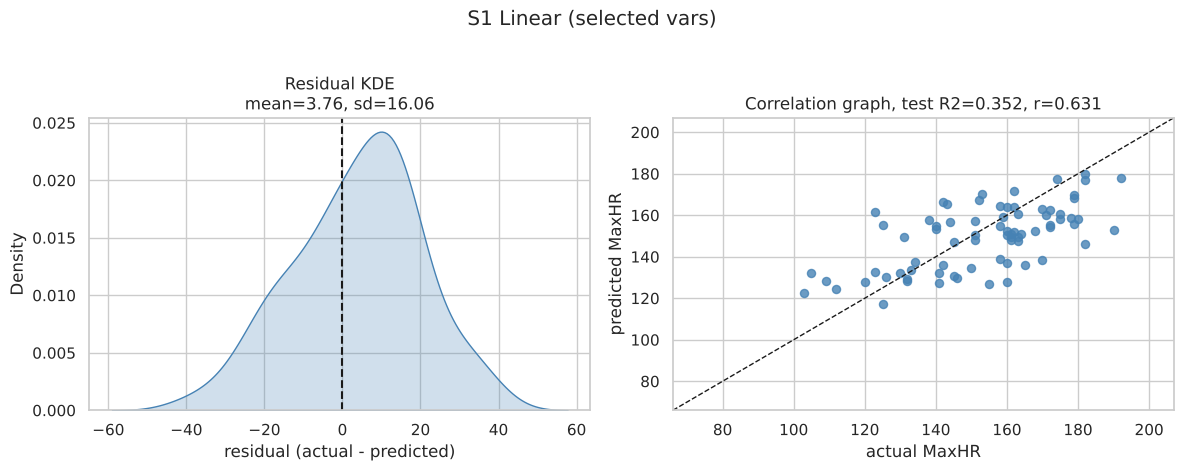

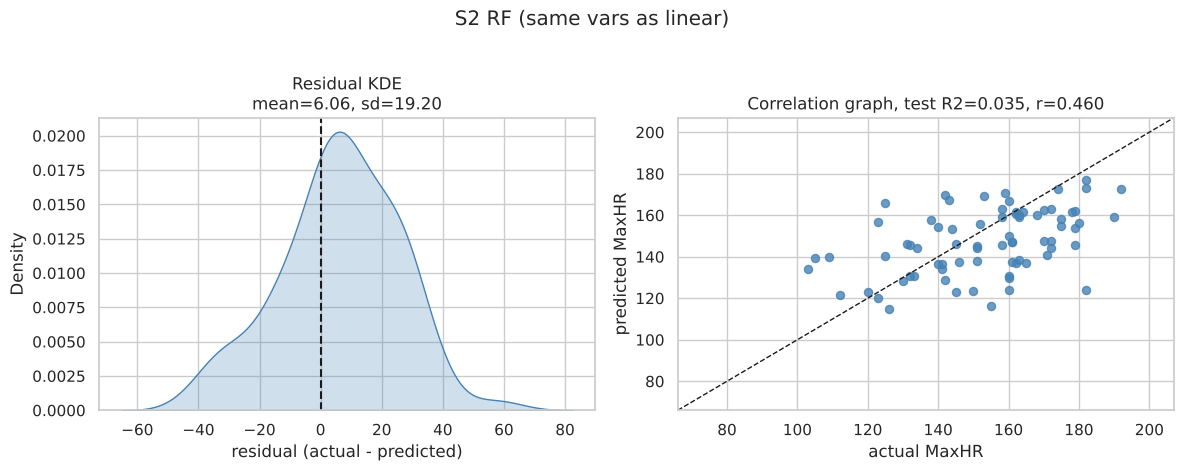

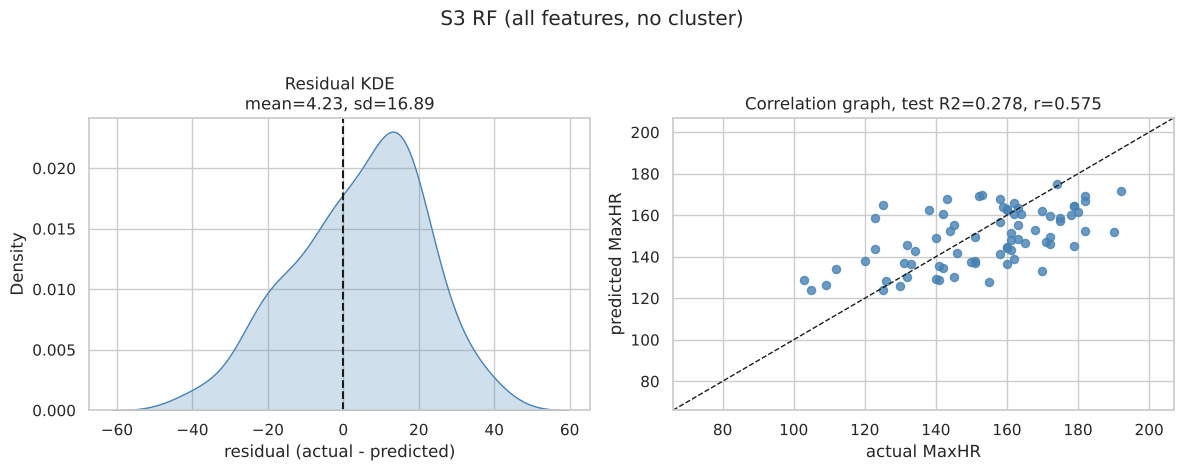

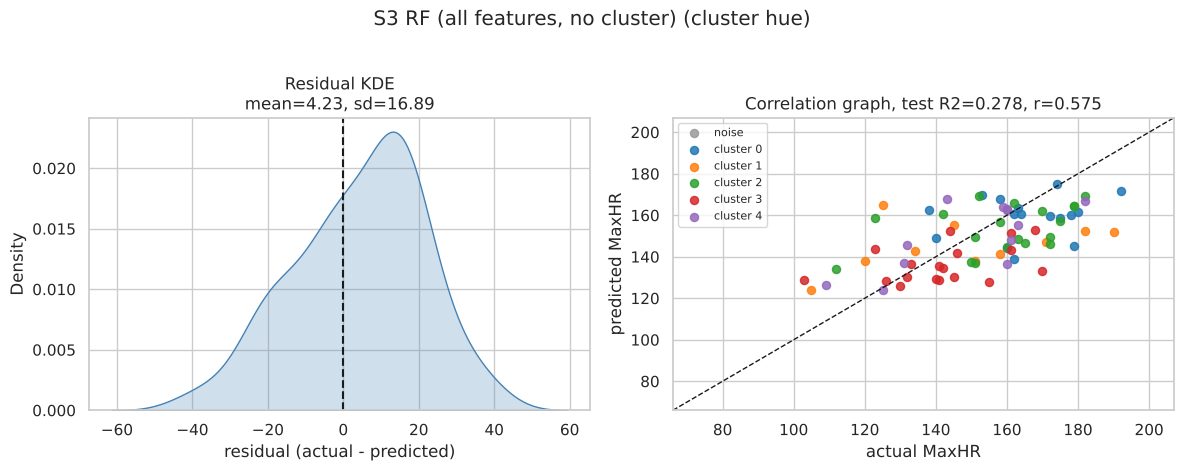

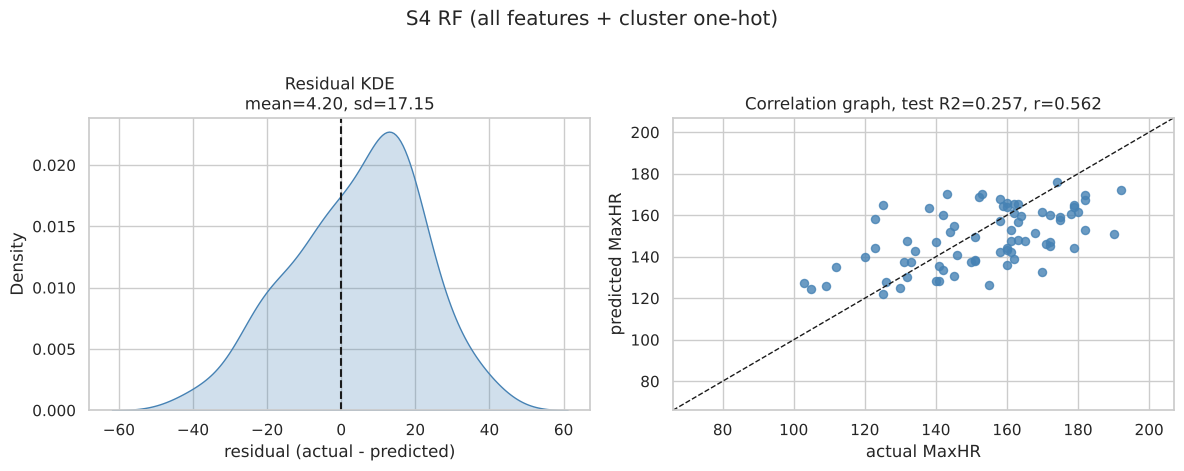

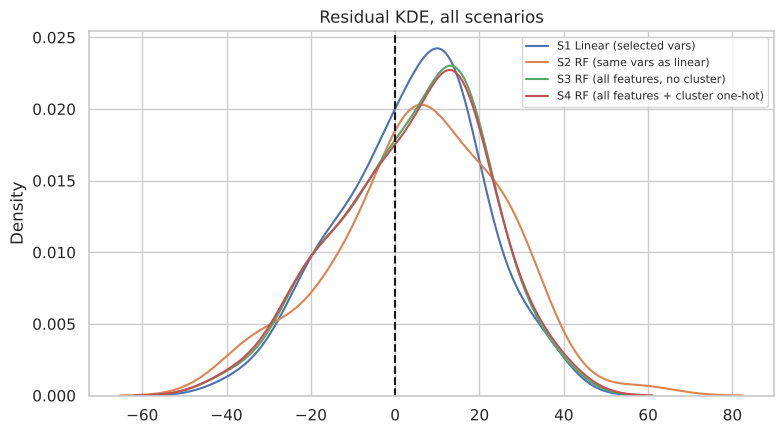

S4 top importances:
{'Age': 0.21, 'Slope': 0.159, 'Oldpeak': 0.123, 'Chol': 0.107, 'RestBP': 0.091, 'ChestPain_asymptomatic': 0.072, 'AHD': 0.058, 'Sex': 0.027, 'Ca': 0.024, 'RestECG': 0.022}


In [14]:
y = df[TARGET].values
ALLFEATS = pd.get_dummies(df.drop(columns=[TARGET, 'cluster']), columns=['ChestPain', 'Thal'], dtype=float)
CLU = pd.get_dummies(df['cluster'].map(lambda k: 'noise' if k == -1 else f'c{k}'), prefix='cl', dtype=float)
scen = {
 'S1 Linear (selected vars)': (LinearRegression(), df[LIN_FEATS].astype(float)),
 'S2 RF (same vars as linear)': (RandomForestRegressor(500, random_state=RS, n_jobs=-1), df[LIN_FEATS].astype(float)),
 'S3 RF (all features, no cluster)': (RandomForestRegressor(500, random_state=RS, n_jobs=-1), ALLFEATS),
 'S4 RF (all features + cluster one-hot)': (RandomForestRegressor(500, random_state=RS, n_jobs=-1), pd.concat([ALLFEATS, CLU], axis=1)),
}
idx_tr, idx_te = train_test_split(np.arange(len(df)), test_size=0.25, random_state=RS)
res, preds = [], {}
for name, (mdl, Xs) in scen.items():
    mdl.fit(Xs.iloc[idx_tr], y[idx_tr]); p = mdl.predict(Xs.iloc[idx_te]); preds[name] = p
    cvr = cross_val_score(type(mdl)(**mdl.get_params()), Xs, y, cv=rkf, scoring='r2')
    res.append(dict(scenario=name, n_features=Xs.shape[1], train_R2=r2_score(y[idx_tr], mdl.predict(Xs.iloc[idx_tr])), test_R2=r2_score(y[idx_te], p), CV_R2_mean=cvr.mean(), CV_R2_sd=cvr.std(), test_RMSE=mean_squared_error(y[idx_te], p)**.5, test_MAE=mean_absolute_error(y[idx_te], p), corr_pred_actual=np.corrcoef(y[idx_te], p)[0, 1]))
    if name.startswith('S1'): print('Linear coefficients:', dict(zip(Xs.columns, mdl.coef_.round(3))), 'intercept', round(mdl.intercept_, 2))
results = pd.DataFrame(res).set_index('scenario').round(3); display(results)
def diag_plots(name, p, hue=False, fn=None):
    r = y[idx_te] - p; fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))
    sns.kdeplot(r, fill=True, ax=ax[0], color='steelblue'); ax[0].axvline(0, color='k', ls='--'); ax[0].set_title(f'Residual KDE\nmean={r.mean():.2f}, sd={r.std():.2f}'); ax[0].set_xlabel('residual (actual - predicted)')
    if hue:
        for k in sorted(set(cl)): m = cl[idx_te] == k; ax[1].scatter(y[idx_te][m], p[m], s=34, color=pal[k], label='noise' if k == -1 else f'cluster {k}', alpha=.85)
        ax[1].legend(fontsize=8)
    else: ax[1].scatter(y[idx_te], p, s=34, alpha=.8, color='steelblue')
    lo, hi = y.min() - 5, y.max() + 5; ax[1].plot([lo, hi], [lo, hi], 'k--', lw=1); ax[1].set_xlim(lo, hi); ax[1].set_ylim(lo, hi)
    ax[1].set_xlabel('actual MaxHR'); ax[1].set_ylabel('predicted MaxHR'); ax[1].set_title(f'Correlation graph, test R2={r2_score(y[idx_te], p):.3f}, r={np.corrcoef(y[idx_te], p)[0,1]:.3f}')
    fig.suptitle(name + (' (cluster hue)' if hue else ''), y=1.02); plt.tight_layout(); plt.savefig(fn, dpi=110, bbox_inches='tight'); plt.show()
names = list(scen)
diag_plots(names[0], preds[names[0]], fn='figs/10_s1.png'); diag_plots(names[1], preds[names[1]], fn='figs/11_s2.png'); diag_plots(names[2], preds[names[2]], fn='figs/12_s3.png')
diag_plots(names[2], preds[names[2]], hue=True, fn='figs/13_s3_hue.png'); diag_plots(names[3], preds[names[3]], fn='figs/14_s4.png')
fig, ax = plt.subplots(figsize=(8, 4.5))
for n in names: sns.kdeplot(y[idx_te] - preds[n], ax=ax, label=n, fill=False)
ax.axvline(0, color='k', ls='--'); ax.legend(fontsize=8); ax.set_title('Residual KDE, all scenarios'); plt.tight_layout(); plt.savefig('figs/15_resid_all.png', dpi=110); plt.show()
m4 = scen[names[3]][0]; imp = pd.Series(m4.feature_importances_, index=scen[names[3]][1].columns).sort_values(ascending=False); print('S4 top importances:'); print(imp.head(10).round(3).to_dict())

### 2.1 Scenario results
Each scenario above shows (1) the residual KDE (test set) and (2) the correlation graph, i.e. predicted vs actual MaxHR with the 45 degree line; S3 is drawn a second time with cluster hue. The last figure overlays all residual KDEs.

* **S1 Linear:** test R2 = **0.352** (CV 0.332 +/- 0.093). Coefficients: AHD -10.7 bpm, ExAng -8.7, Slope -9.3, Age -0.87 bpm per year, RestBP +0.16. Residuals are roughly bell-shaped (sd 16.1) with a mean of +3.8 bpm: this particular test split happens to contain patients with slightly higher MaxHR than the training set, so every model under-predicts a little on it (+3.8 to +6.1 bpm in all four scenarios; this is a split effect, not a model-specific bias). Train R2 (0.376) is almost equal to test R2 -> no overfit.
* **S2 RF same variables:** test R2 = **0.035** (CV 0.167). Train R2 0.90 vs test 0.04 is severe overfitting: with 5 mostly binary predictors and a noisy, near-linear signal, 500 fully-grown trees memorise the training noise. The linear model is clearly the better fit for this signal.
* **S3 RF all features, no cluster:** test R2 = **0.278** (CV 0.308). More features recover most of the signal (Age, Slope, Oldpeak, Chol, RestBP are the top importances), but forest predictions are shrunk toward the mean (flatter correlation graph) and still below the linear model.
* **S3 with cluster hue:** mean test residuals per cluster are +6.3 (c0), +2.5 (c1), +5.0 (c2), +6.0 (c3), -1.1 (c4), i.e. the same direction as the global +4.2 shift, with only cluster 4 near zero; with 10-19 test points per cluster these differences are within noise, so no cluster is clearly mis-modelled. Cluster 0/2 points sit at higher actual values and cluster 3 at lower, as expected from the profile table, and the forest already captures that level difference through the original features. Forest predictions are compressed toward the mean (flatter than the 45 degree line).
* **S4 RF all features + cluster:** test R2 = **0.257** (CV 0.310). Essentially identical to S3.

### 2.2 Did cluster information improve prediction?
**No.** S3 -> S4: test R2 0.278 -> 0.257 (-0.021), CV R2 0.308 -> 0.310 (+0.002 with sd 0.13) - the difference is far inside the noise. The reason is structural: the clusters were derived *only from the other features* (they are mostly re-encodings of `ChestPain`, `Thal`, `AHD`, `ExAng`, `Oldpeak`), so they add no information that a forest with those features does not already have; the label is a function of X, and trees can recreate it. Cluster membership is useful for **interpretation** (describing patient groups) but not for prediction here. The best model overall is the simple, interpretable **linear model (S1)**, the more complex RFs do not beat it.

### 2.3 Simpson's paradox check
Simpson's paradox would show up as a pooled correlation whose sign is reversed (or vanishes) inside the clusters. For every pair of continuous variables we compare the pooled Pearson r with the within-cluster r:

In [15]:
rows = []
for a, b in itertools.combinations(CONT, 2):
    ov = stats.pearsonr(df[a], df[b])[0]; ws = {k: stats.pearsonr(g[a], g[b])[0] for k, g in df[df.cluster != -1].groupby('cluster') if len(g) > 10}
    w = np.array(list(ws.values())); rows.append(dict(pair=f'{a} vs {b}', overall_r=round(ov, 2), **{f'c{k}': round(v, 2) for k, v in ws.items()}, n_clusters_opposite_sign=int((np.sign(w) != np.sign(ov)).sum()), mean_within_r=round(w.mean(), 2)))
simp = pd.DataFrame(rows).set_index('pair'); display(simp)

,overall_r,c0,c1,c2,c3,c4,n_clusters_opposite_sign,mean_within_r
pair,,,,,,,,
Age vs RestBP,0.29,0.40,0.36,0.32,0.26,0.09,0,0.29
Age vs Chol,0.20,0.35,0.14,0.30,0.01,0.21,0,0.20
Age vs MaxHR,-0.39,-0.55,-0.29,-0.51,-0.07,-0.43,0,-0.37
Age vs Oldpeak,0.20,0.12,0.02,0.17,0.24,0.15,0,0.14
RestBP vs Chol,0.13,0.25,0.24,0.02,0.17,0.26,0,0.19
RestBP vs MaxHR,-0.05,0.18,-0.16,-0.04,-0.01,0.10,2,0.01
RestBP vs Oldpeak,0.19,-0.03,-0.10,0.19,0.26,0.11,2,0.09
Chol vs MaxHR,-0.00,-0.23,0.06,0.03,0.05,0.05,4,-0.01
Chol vs Oldpeak,0.04,0.19,0.11,-0.01,0.07,0.03,1,0.08


* **No classic Simpson's reversal** of a *meaningful* relationship: the two strongest pooled relations (`Age`-`MaxHR`, `Age`-`RestBP`) keep their sign in all 5 clusters, and `MaxHR`-`Oldpeak` keeps its sign in all 5 clusters (but weaker: -0.35 pooled vs -0.21 mean within; a *confounding/attenuation* effect, not a reversal).
* **Weak/mild signs of the paradox only for pairs that are about zero overall:** `Chol`-`MaxHR` (pooled 0.00, but -0.23 in cluster 0 and +0.05 to +0.06 in others), `RestBP`-`MaxHR` (-0.05 pooled, +0.18 in cluster 0 vs -0.16 in cluster 1), `RestBP`-`Oldpeak` (+0.19 pooled, negative in clusters 0 and 1). These are small, within-cluster samples of 39-81 points with sampling noise of about +/-0.15, so we cannot claim a real paradox; a sign flip of an r of 0.1-0.2 with n~40-80 is not statistically significant.
* **Conclusion:** we do **not** observe a convincing Simpson's paradox in this dataset. We observe weaker within-cluster relationships (between-cluster confounding of MaxHR-Oldpeak) and a few noise-level sign changes. This is consistent with Section 2.2: clusters do not change the linear story, so including them did not help predictions.

## 3. Overall conclusions
1. `MaxHR` is only moderately predictable (R2 about 0.3-0.35 at best) from this clinical data; the strongest drivers are the disease label, exercise angina, ST-slope, `Oldpeak` and age.
2. Conventional metrics and PPS agree on *which* variables matter but PPS is much more conservative; PPS (0) understates linear effects (`Age`, `Oldpeak`).
3. UMAP + HDBSCAN finds 5 well-defined patient groups but they are driven by the categorical variables.
4. Linear model > random forest here; cluster information does not improve prediction; no real Simpson's paradox.